# End-to-End Pattern Recognition Workbench - guided tour

**Authors:** Saksham Bakshi and Anjika Shokeen  |  B.Tech final-year mini project (Pattern Recognition)

This notebook walks through the complete chain implemented in the `prwb` package:

1. **Data** - three modalities (handwritten-digit images, synthetic waveform signals, tabular medical/chemical data)
2. **Feature extraction** - HOG, LBP, GLCM, Hu moments, spectral/Hjorth/auto-correlation descriptors (all from scratch in NumPy)
3. **Statistical analysis** - normality, ANOVA/Kruskal-Wallis with FDR control, effect sizes, Bhattacharyya separability, outliers
4. **Classification** - k-NN, Bayes (QDA/LDA/naive), Parzen, softmax regression and an MLP with back-propagation (from scratch) vs. SVM / forests / boosting
5. **Clustering** - k-means++, EM-GMM, fuzzy c-means (from scratch) vs. hierarchical / spectral / DBSCAN / HDBSCAN
6. **Performance evaluation** - repeated stratified CV, ROC / calibration, McNemar, corrected resampled t-test, Friedman-Nemenyi

Everything runs offline (datasets ship with scikit-learn or are synthesised) and is seeded for reproducibility.

In [1]:
import os, sys, warnings, time
warnings.filterwarnings("ignore")
# make the repository importable whether the notebook is run from notebooks/ or from the repository root
ROOT = os.path.abspath("..") if os.path.exists(os.path.join("..", "prwb")) else os.path.abspath(".")
sys.path.insert(0, ROOT)
FIG = os.path.join(ROOT, "results", "notebook_figs"); os.makedirs(FIG, exist_ok=True)

import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 4); pd.set_option("display.width", 140)

import prwb
from prwb import datasets as D
from prwb.features import build_features, PCAScratch, Standardizer, LDAProjection, FEATURE_SETS
from prwb.features.image import hog_cells, lbp_codes
from prwb.stats import anova_table, normality_tests, bhattacharyya_matrix, class_separability, mahalanobis_outliers, correlation_summary
from prwb.classifiers import get_classifiers
from prwb.clustering import get_clusterers, estimate_eps, sweep_k, gap_statistic
from prwb.evaluation import plots as pl
from prwb.evaluation.metrics import (cross_validate_model, clustering_scores, mcnemar_test, corrected_resampled_ttest,
                                     friedman_nemenyi, bootstrap_ci)
print("prwb", prwb.__version__)

prwb 1.0.0


## 1. Data - three modalities

In [2]:
datasets = {n: D.load_dataset(n) for n in D.list_datasets()}
pd.DataFrame([{"dataset": n, "modality": d.modality, "samples": d.n_samples,
               "pattern shape": "x".join(map(str, d.X.shape[1:])), "classes": d.n_classes,
               "smallest class": int(d.class_counts().min()), "largest class": int(d.class_counts().max())}
              for n, d in datasets.items()])

,dataset,modality,samples,pattern shape,classes,smallest class,largest class
0,breast_cancer,tabular,569,30,2,212,357
1,digits,image,1797,16x16,10,174,183
2,signals,signal,1200,256,6,200,200
3,wine,tabular,178,13,3,48,71


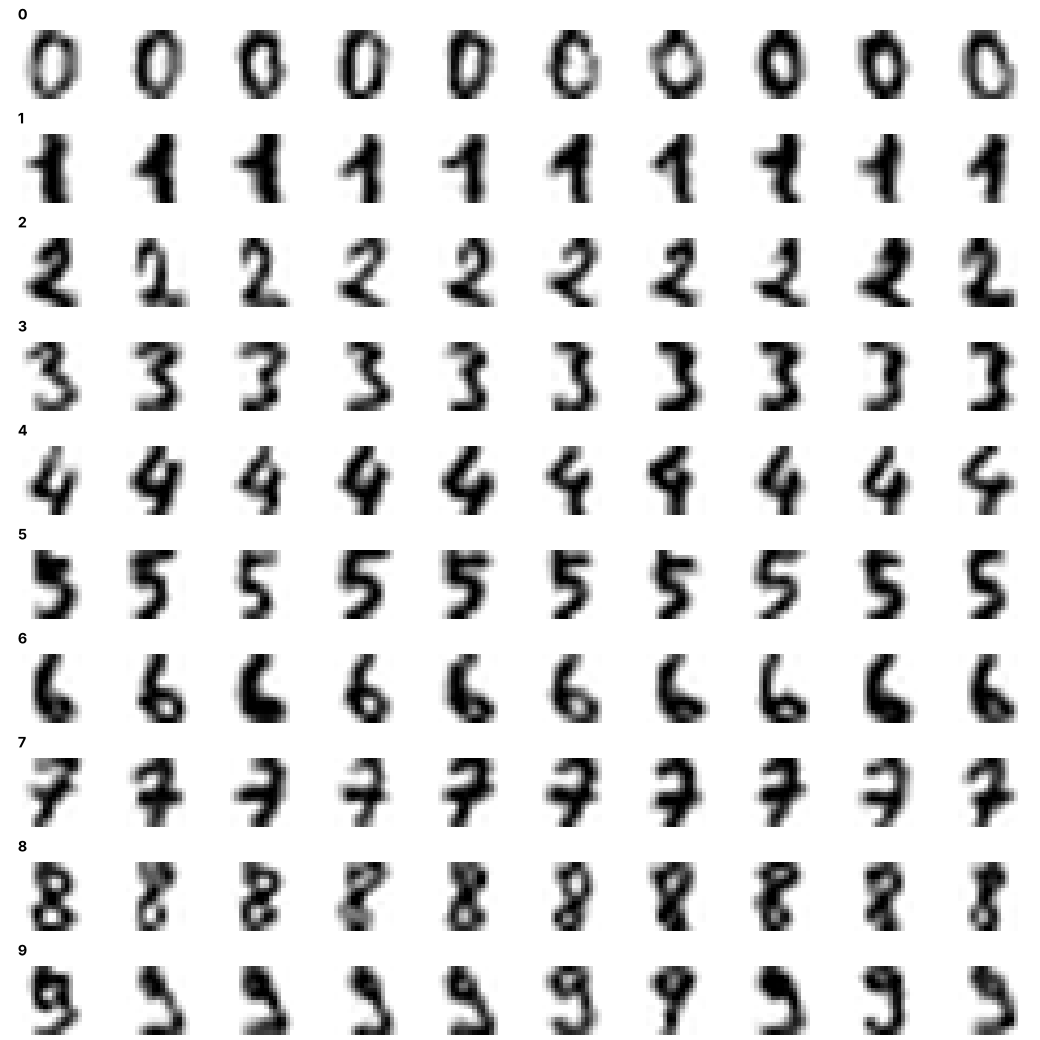

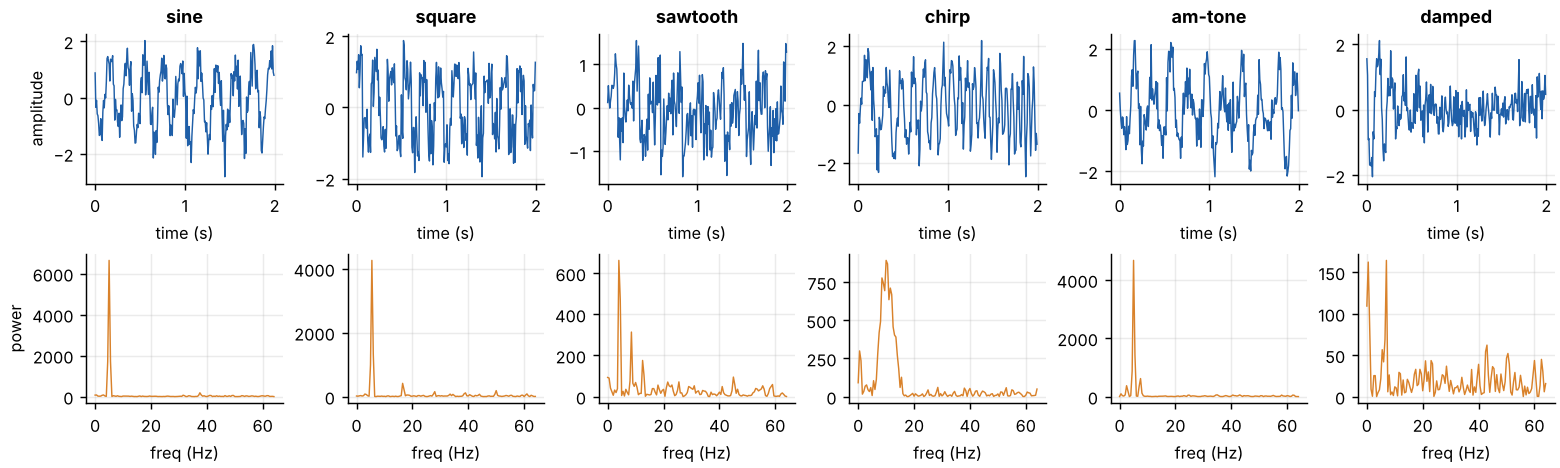

In [3]:
dg, sg = datasets["digits"], datasets["signals"]
display(Image(pl.plot_image_grid(dg.X, dg.y, dg.class_names, 10, f"{FIG}/digits.png")))
display(Image(pl.plot_signal_examples(sg.X, sg.y, sg.class_names, sg.meta["fs"], f"{FIG}/signals.png")))

## 2. Feature extraction

Descriptors are implemented from scratch. The HOG cell histograms and the LBP code map of one digit are shown below.

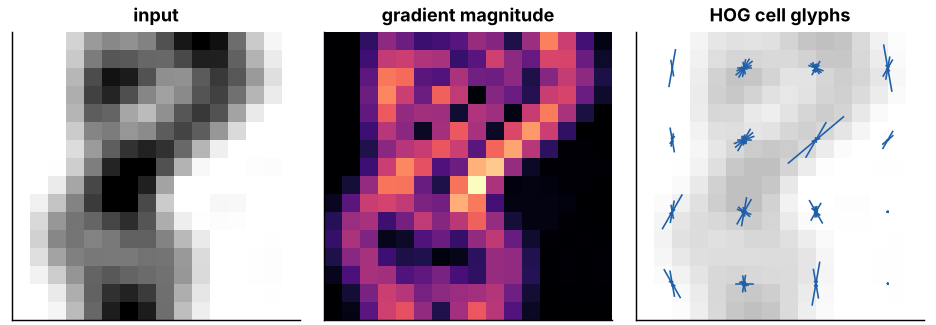

digits / raw          -> matrix (1797, 256)
digits / zoning       -> matrix (1797, 16)


digits / hu           -> matrix (1797, 7)
digits / glcm         -> matrix (1797, 12)
digits / lbp          -> matrix (1797, 236)


digits / hog          -> matrix (1797, 324)
digits / hog+lbp      -> matrix (1797, 560)


digits / handcrafted  -> matrix (1797, 617)


In [4]:
i = int(np.flatnonzero(dg.y == 8)[3])
display(Image(pl.plot_hog_visual(dg.X[i], hog_cells(dg.X[i][None], 4, 9)[0], f"{FIG}/hog.png")))
for s in FEATURE_SETS["image"]:
    fm = build_features(dg, s)
    print(f"digits / {s:12s} -> matrix {fm.shape}")

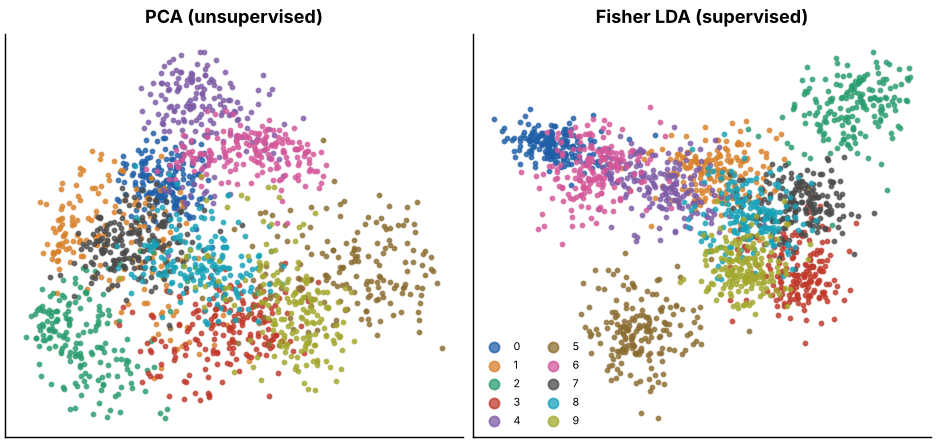

In [5]:
fm = build_features(dg, "hog+lbp")
Z = PCAScratch(30).fit_transform(Standardizer().fit_transform(fm.X))
emb = {"PCA (unsupervised)": Z[:, :2], "Fisher LDA (supervised)": LDAProjection(2).fit(Z, dg.y).transform(Z)}
display(Image(pl.plot_embeddings(emb, dg.y, dg.class_names, f"{FIG}/emb.png")))

## 3. Statistical analysis of the feature space

In [6]:
fmh = build_features(dg, "handcrafted")
an = anova_table(fmh.X, dg.y, fmh.names)
print("features:", fmh.X.shape[1], "| significant after BH (q<0.05):", int((an.anova_q_BH < 0.05).sum()))
an.head(8)[["feature", "anova_F", "eta_squared", "omega_squared", "anova_q_BH", "levene_p"]]

features: 617 | significant after BH (q<0.05): 611


,feature,anova_F,eta_squared,omega_squared,anova_q_BH,levene_p
0,profiles_10,407.2770,0.6723,0.6705,0.0,4.9638e-70
1,hu_1,375.2132,0.6539,0.6521,0.0,1.1599e-33
2,profiles_1,356.9331,0.6426,0.6406,0.0,1.7540e-26
3,profiles_9,338.4105,0.6302,0.6282,0.0,6.7153e-40
4,hog_134,324.2668,0.6202,0.6182,0.0,1.5023e-104
5,profiles_14,314.8591,0.6133,0.6112,0.0,1.6153e-54
6,lbp_73,300.4147,0.6021,0.5999,0.0,1.7165e-162
7,profiles_0,296.4985,0.5989,0.5968,0.0,6.5862e-39


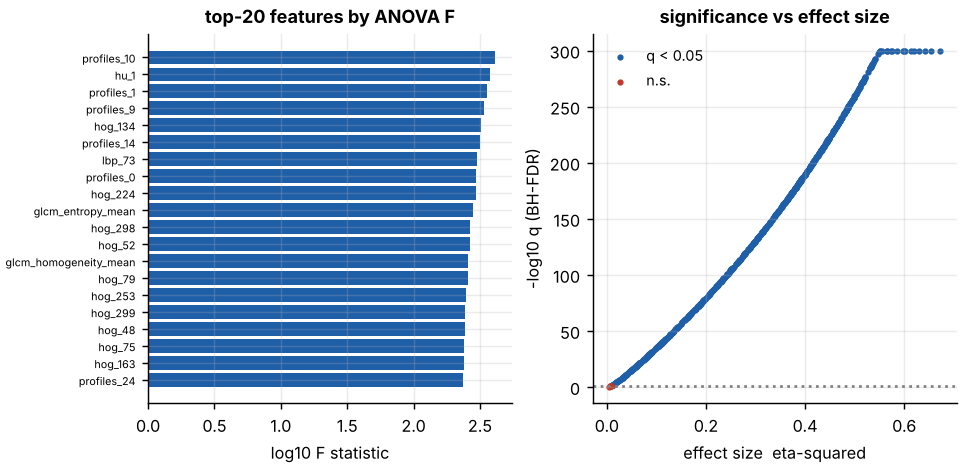

fraction of features that look Gaussian (Shapiro-Wilk, 5%): 0.013
{'n_features': 617, 'n_constant': 0, 'mean_abs_corr': 0.103, 'n_pairs_above_threshold': 306, 'threshold': 0.9, 'condition_number': 5.410757400897889e+16, 'effective_rank': 10.437}


In [7]:
display(Image(pl.plot_anova_top(an, f"{FIG}/anova.png", 20)))
nt = normality_tests(fmh.X, fmh.names)
print("fraction of features that look Gaussian (Shapiro-Wilk, 5%):", round(nt.normal_at_5pct.mean(), 3))
cs = correlation_summary(fmh.X, fmh.names)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in cs.items() if k not in ("corr", "kept_index")})

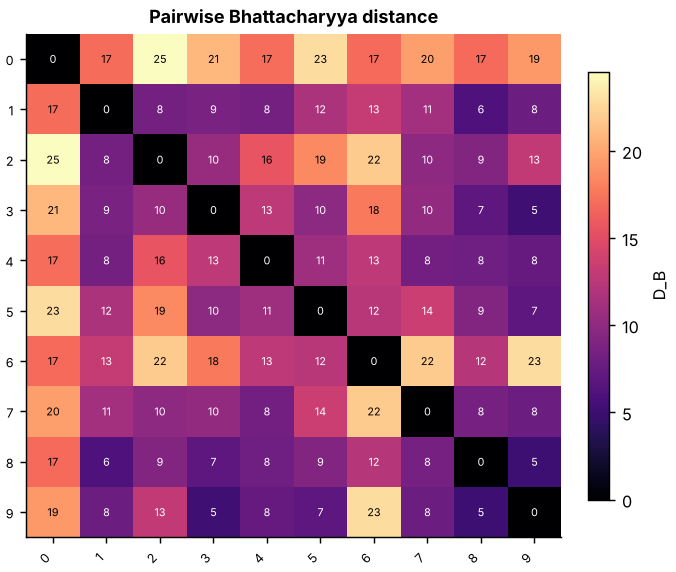

Mahalanobis outliers (chi2, alpha=0.001): 4 of 1797   |  class separability: {'J_trace_SwInv_Sb': 37.98682384719506, 'trace_Sb_over_trace_Sw': 1.1816368802744006}


In [8]:
Zs = PCAScratch(20).fit_transform(Standardizer().fit_transform(fmh.X))
B = bhattacharyya_matrix(Zs, dg.y)
display(Image(pl.plot_heatmap(B, dg.class_names, dg.class_names, f"{FIG}/bhatt.png", "Pairwise Bhattacharyya distance", cmap="magma",
                              fmt="{:.0f}", annotate=True, figsize=(5.2, 4.4), cbar_label="D_B")))
d2, thr, flag = mahalanobis_outliers(Zs)
print(f"Mahalanobis outliers (chi2, alpha=0.001): {flag.sum()} of {len(flag)}   |  class separability: {class_separability(Zs, dg.y)}")

## 4. Classification benchmark (repeated stratified cross-validation)

Every model is wrapped in a `Pipeline(Standardizer -> classifier)`, so the scaler is re-fitted inside each training fold (no leakage).
Models marked *scratch* are implemented in NumPy in this repository.

In [9]:
fm = build_features(dg, "hog+lbp")
names = ["MinDist", "kNN", "Bayes-LDA", "Bayes-QDA", "Parzen", "Softmax", "MLP", "SVM-RBF", "LogReg(sk)", "RandomForest"]
zoo = get_classifiers(0, names=names)
rows, folds, oof = [], {}, {}
for n, m in zoo.items():
    t0 = time.time()
    r = cross_validate_model(m, fm.X, dg.y, n_splits=5, n_repeats=2, seed=0)
    f = r["folds"]; lo, hi = bootstrap_ci(f.accuracy.values)
    rows.append({"classifier": n, "scratch": n in ("MinDist", "kNN", "Bayes-LDA", "Bayes-QDA", "Parzen", "Softmax", "MLP"),
                 "accuracy": f.accuracy.mean(), "ci95_low": lo, "ci95_high": hi, "macro_F1": f.macro_f1.mean(), "MCC": f.mcc.mean(),
                 "AUC": f.roc_auc.mean(), "ECE": f.ece.mean(), "fit_s": r["fit_time"]})
    folds[n] = f.accuracy.values; oof[n] = (r["oof_pred"], r["oof_proba"])
res = pd.DataFrame(rows).sort_values("accuracy", ascending=False).reset_index(drop=True)
res

,classifier,scratch,accuracy,ci95_low,ci95_high,macro_F1,MCC,AUC,ECE,fit_s
0,SVM-RBF,False,0.9947,0.9930,0.9964,0.9947,0.9941,0.9992,0.0558,1.5592
1,LogReg(sk),False,0.9933,0.9905,0.9961,0.9933,0.9926,1.0000,0.0094,0.0663
2,Bayes-LDA,True,0.9903,0.9878,0.9928,0.9902,0.9892,0.9999,0.0098,0.1030
3,kNN,True,0.9900,0.9880,0.9919,0.9900,0.9889,0.9996,0.0131,0.0119
4,MLP,True,0.9866,0.9825,0.9905,0.9866,0.9852,0.9998,0.0097,1.1694
5,RandomForest,False,0.9858,0.9822,0.9892,0.9857,0.9843,0.9997,0.2341,2.3198
6,Bayes-QDA,True,0.9841,0.9800,0.9880,0.9841,0.9824,0.9973,0.0159,0.1252
7,Softmax,True,0.9800,0.9711,0.9878,0.9800,0.9778,0.9994,0.0173,0.3844
8,MinDist,True,0.9647,0.9605,0.9691,0.9647,0.9609,0.9990,0.0353,0.0133
9,Parzen,True,0.9477,0.9413,0.9533,0.9476,0.9422,0.9971,0.7794,0.0206


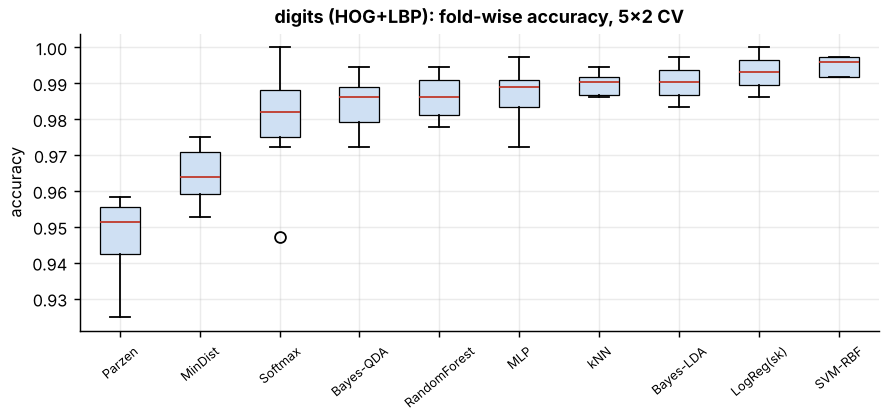

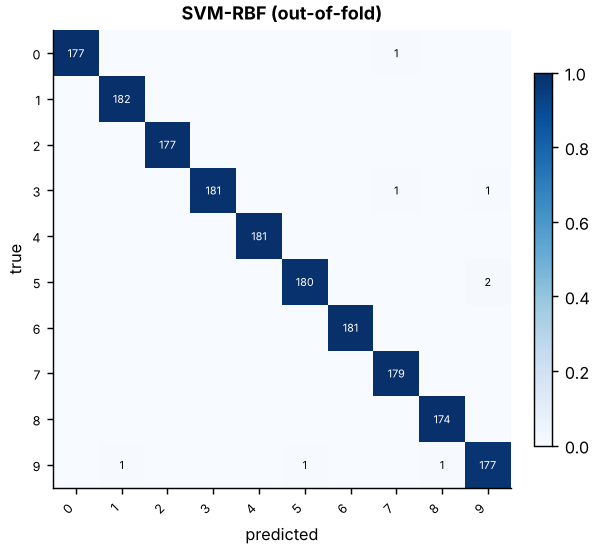

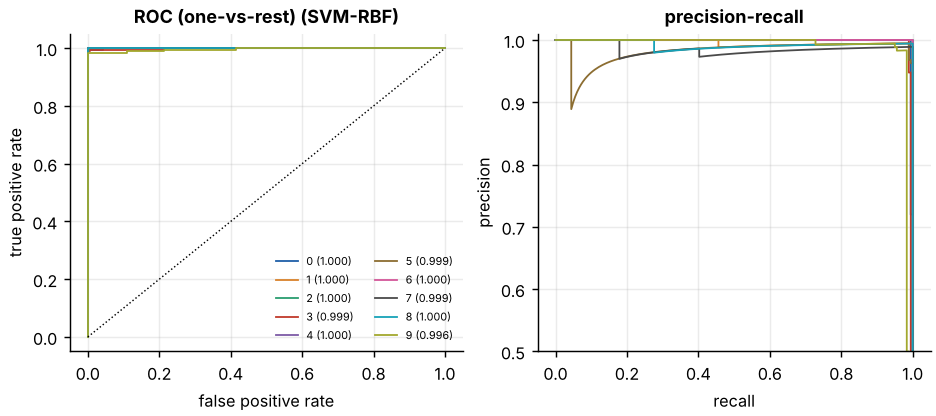

In [10]:
display(Image(pl.plot_cv_boxplot(folds, f"{FIG}/box.png", "accuracy", "digits (HOG+LBP): fold-wise accuracy, 5x2 CV")))
best = res.classifier[0]
display(Image(pl.plot_confusion(dg.y, oof[best][0], dg.class_names, f"{FIG}/cm.png", f"{best} (out-of-fold)")))
display(Image(pl.plot_roc_multiclass(dg.y, oof[best][1], dg.class_names, f"{FIG}/roc.png", f"({best})")))

SVM-RBF vs LogReg(sk):  McNemar p=0.683  (n01=4, n10=2)   corrected-t p=0.522


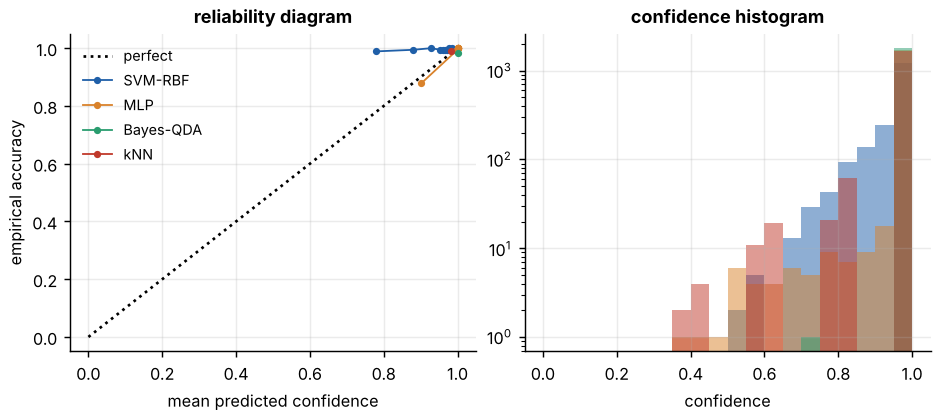

In [11]:
# is the best model *significantly* better than the runner-up?  (McNemar on paired OOF predictions + Nadeau-Bengio corrected t-test)
second = res.classifier[1]
mc = mcnemar_test(dg.y, oof[best][0], oof[second][0])
n = dg.n_samples; nte = n // 5
ct = corrected_resampled_ttest(folds[best], folds[second], n - nte, nte)
print(f"{best} vs {second}:  McNemar p={mc['p']:.3f}  (n01={mc['n01']}, n10={mc['n10']})   corrected-t p={ct['p']:.3f}")
display(Image(pl.plot_calibration(dg.y, {k: oof[k][1] for k in [best, "MLP", "Bayes-QDA", "kNN"]}, f"{FIG}/cal.png")))

## 5. Signals: waveform-family recognition (1-D patterns)

In [12]:
fs_ = build_features(sg, "handcrafted")
print("signal feature matrix:", fs_.shape)
rows = []
for s in ["raw", "time", "spectral", "time+hjorth", "handcrafted"]:
    f_ = build_features(sg, s)
    r = cross_validate_model(get_classifiers(0, names=["SVM-RBF"])["SVM-RBF"], f_.X, sg.y, 5, 1, 0, keep_oof=False)
    rows.append({"feature set": s, "dims": f_.X.shape[1], "SVM-RBF accuracy": r["folds"].accuracy.mean()})
pd.DataFrame(rows)

signal feature matrix: (1200, 33)


,feature set,dims,SVM-RBF accuracy
0,raw,256,0.5667
1,time,9,0.7950
2,spectral,16,0.9675
3,time+hjorth,12,0.8692
4,handcrafted,33,0.9925


## 6. Clustering (no labels used for fitting)

In [13]:
Zc = PCAScratch(30).fit_transform(Standardizer().fit_transform(fm.X))
rows = []
for name, model in get_clusterers(10, 0, estimate_eps(Zc, 5, 0.7)).items():
    lab = model.fit_predict(Zc)
    rows.append({"algorithm": name, **{k: v for k, v in clustering_scores(Zc, dg.y, lab).items() if k in ("ARI", "NMI", "cluster_acc", "purity", "silhouette", "n_clusters")}})
cl = pd.DataFrame(rows).sort_values("ARI", ascending=False).reset_index(drop=True); cl

,algorithm,ARI,NMI,purity,cluster_acc,n_clusters,silhouette
0,Agglomerative-Ward,0.9111,0.9355,0.9583,0.9583,10,0.2281
1,Spectral,0.8708,0.9465,0.8976,0.8826,10,0.2328
2,GMM-full (scratch),0.7954,0.8817,0.8726,0.8392,10,0.2394
3,KMeans (scratch),0.7604,0.8382,0.8514,0.8180,10,0.2379
4,GMM-diag (scratch),0.7582,0.8619,0.8570,0.8236,10,0.2375
5,Fuzzy C-Means,0.7553,0.8338,0.8481,0.8158,10,0.2365
6,KMeans (sklearn),0.7528,0.8491,0.8520,0.8169,10,0.2298
7,Agglomerative-Average,0.6397,0.8563,0.6978,0.6761,10,0.1876
8,DBSCAN,0.5607,0.7422,0.6795,0.6539,12,0.1555
9,HDBSCAN,0.2871,0.6562,0.6578,0.6043,12,0.3617


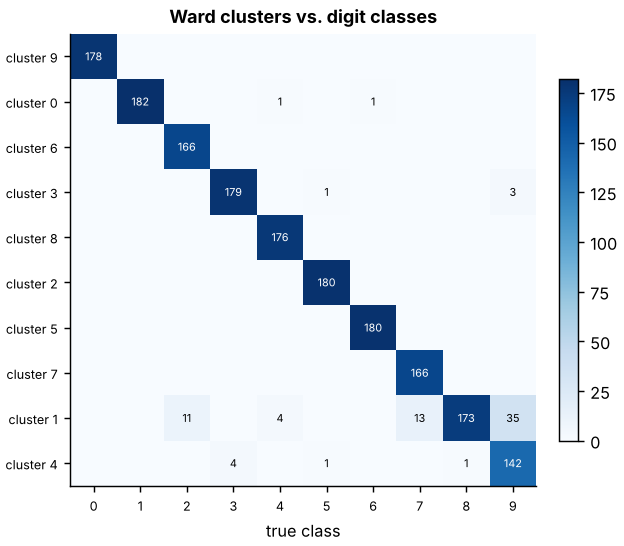

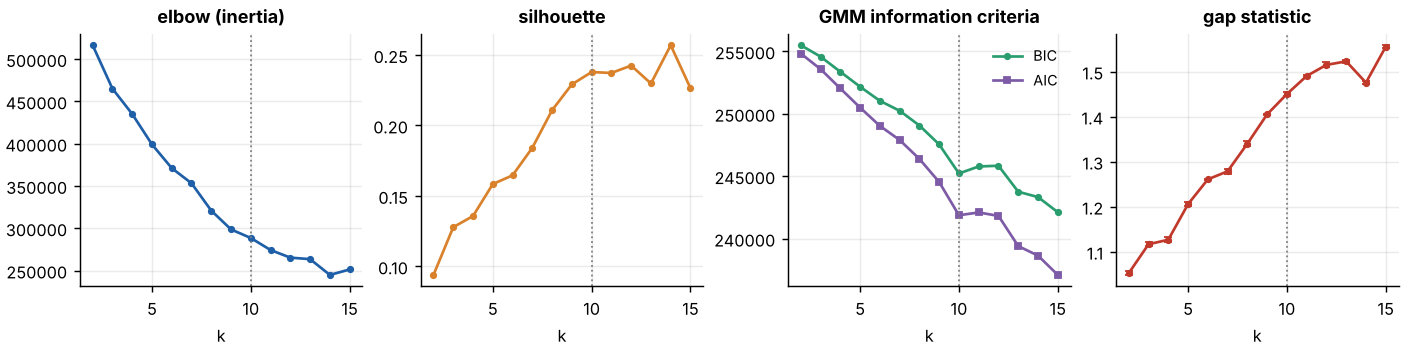

In [14]:
lab = get_clusterers(10, 0)["Agglomerative-Ward"].fit_predict(Zc)
display(Image(pl.plot_contingency(dg.y, lab, dg.class_names, f"{FIG}/cont.png", "Ward clusters vs. digit classes")))
ks = list(range(2, 16))
sw, gp = sweep_k(Zc, ks, 0), gap_statistic(Zc, ks, n_refs=5, seed=0)
display(Image(pl.plot_k_selection(sw, gp, f"{FIG}/ksel.png", true_k=10)))

## 7. Train a deployable recogniser and predict a new digit image

In [15]:
from prwb.pipeline import train_final_model
from prwb.features.image import extract_image_features
model = train_final_model("digits", "hog+lbp", "SVM-RBF")
i = int(np.flatnonzero(dg.y == 7)[10])
p = model.predict_proba(extract_image_features(dg.X[i][None], FEATURE_SETS["image"]["hog+lbp"])[0])[0]
print("true label: 7 | predicted:", int(np.argmax(p)), f"| confidence {p.max():.2%}")

true label: 7 | predicted: 7 | confidence 96.77%


## 8. Summary

* The full chain (features -> statistics -> classification -> clustering -> evaluation) runs from one package and one CLI (`python -m prwb --help`).
* From-scratch implementations are numerically validated against scikit-learn / scikit-image / SciPy in the unit-test suite (`pytest`).
* The complete benchmark behind the project report is reproduced by `python scripts/run_experiments.py`.